# Analizando una Imagen

In [1]:
import matplotlib.pyplot as plt 
img = plt.imread('beagle.jpg')
img.shape

img[10,10]

array([22, 35,  5], dtype=uint8)

In [2]:
rojo = img[10, 10, 0]
verde = img[10, 10, 1]
azul = img[10, 10, 2]

print("Rojo:", rojo)
print("Verde:", verde)
print("Azul:", azul)

Rojo: 22
Verde: 35
Azul: 5


Dimensiones: (1024, 1024, 3)
Píxel [10,10]: [22 35  5]


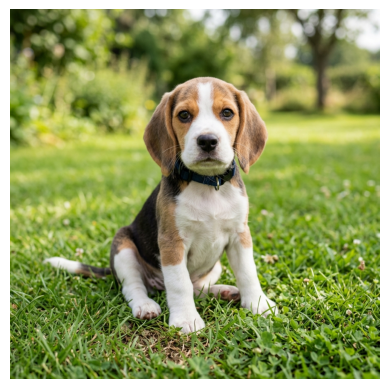

In [3]:
print("Dimensiones:", img.shape)
print("Píxel [10,10]:", img[10,10])

plt.imshow(img)
plt.axis("off")
plt.show()

In [4]:
print("Valor mínimo:", img.min())
print("Valor máximo:", img.max())
print("Media:", img.mean())
print("Desviación estándar:", img.std())

Valor mínimo: 0
Valor máximo: 255
Media: 119.40487066904704
Desviación estándar: 60.935034798738684


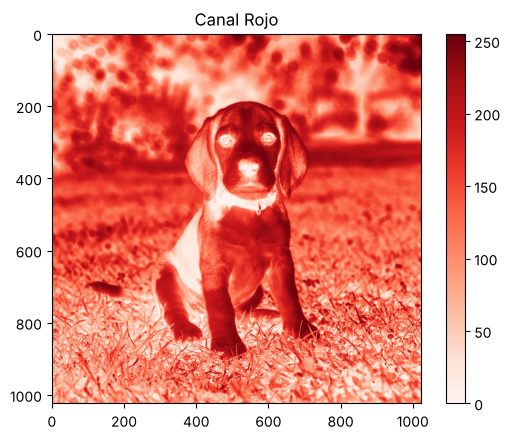

In [5]:
plt.imshow(img[:, :, 0], cmap="Reds")
plt.colorbar()
plt.title("Canal Rojo")
plt.show()

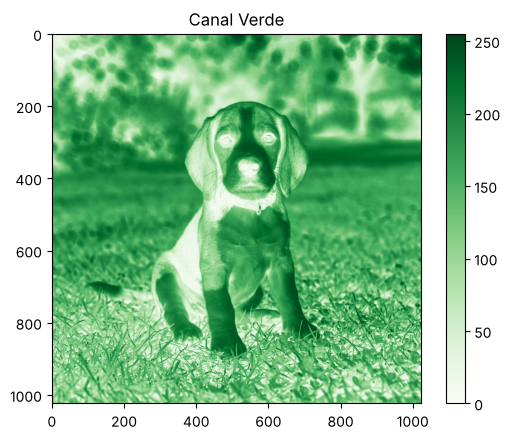

In [6]:
plt.imshow(img[:, :, 1], cmap="Greens")
plt.colorbar()
plt.title("Canal Verde")
plt.show()

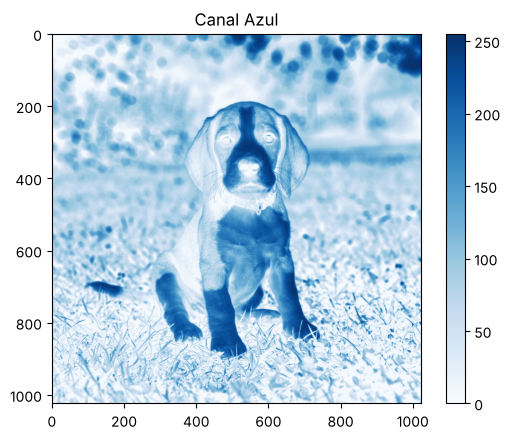

In [7]:
plt.imshow(img[:, :, 2], cmap="Blues")
plt.colorbar()
plt.title("Canal Azul")
plt.show()

In [8]:
media_rojo = img[:, :, 0].mean()
media_verde = img[:, :, 1].mean()
media_azul = img[:, :, 2].mean()

print("Rojo:", media_rojo)
print("Verde:", media_verde)
print("Azul:", media_azul)

Rojo: 133.204363822937
Verde: 145.15760898590088
Azul: 79.85263919830322


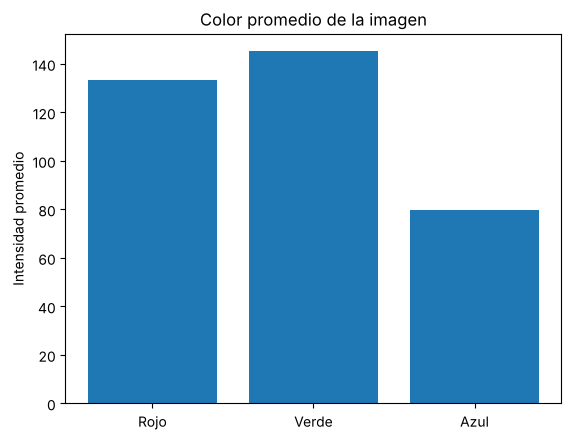

In [9]:
canales = ["Rojo", "Verde", "Azul"]
valores = [media_rojo, media_verde, media_azul]

plt.bar(canales, valores)
plt.ylabel("Intensidad promedio")
plt.title("Color promedio de la imagen")
plt.show()

In [10]:
import pandas as pd

datos = img.reshape(-1, 3)

df = pd.DataFrame(
    datos,
    columns=["Rojo", "Verde", "Azul"]
)

print(df.head())

   Rojo  Verde  Azul
0    29     46    10
1    27     44     8
2    30     45    12
3    28     43    10
4    29     43     8


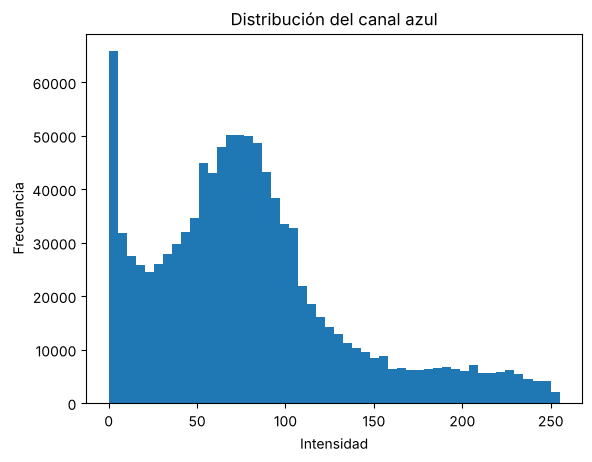

In [11]:
plt.hist(img[:,:,2].ravel(), bins=50)
plt.title("Distribución del canal azul")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.show()

## Ejercicio 1: Escala de grises

Forma original: (1024, 1024, 3)
Forma en gris: (1024, 1024)
Diferencia media entre métodos: 14.762011577606195


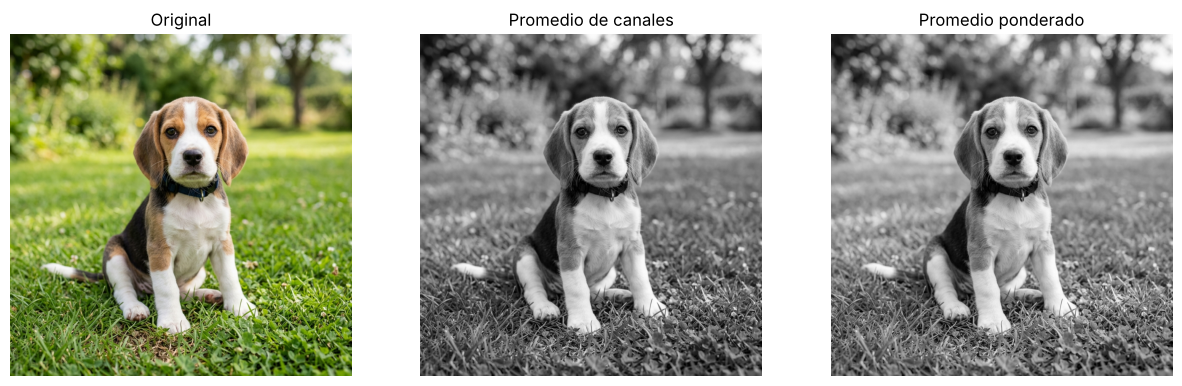

In [12]:
import numpy as np

gris_promedio = img.mean(axis=2)
gris_ponderado = img @ np.array([0.299, 0.587, 0.114])

print("Forma original:", img.shape)
print("Forma en gris:", gris_promedio.shape)
print("Diferencia media entre métodos:", np.abs(gris_promedio - gris_ponderado).mean())

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
ejes[0].imshow(img)
ejes[0].set_title("Original")
ejes[1].imshow(gris_promedio, cmap="gray")
ejes[1].set_title("Promedio de canales")
ejes[2].imshow(gris_ponderado, cmap="gray")
ejes[2].set_title("Promedio ponderado")
for eje in ejes:
    eje.axis("off")
plt.show()

## Ejercicio 2: Recorte, espejo y negativo

Tamaño del recorte: (330, 370, 3)


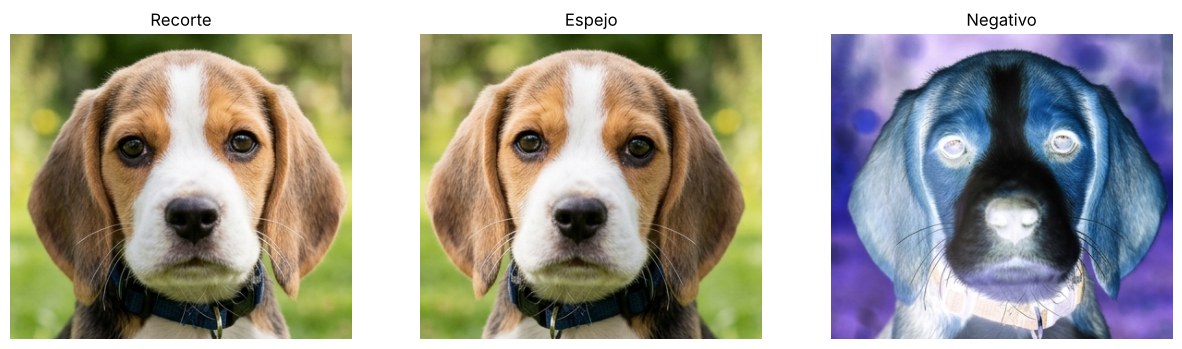

In [13]:
cara = img[170:500, 350:720]
espejo = cara[:, ::-1]
negativo = 255 - cara

print("Tamaño del recorte:", cara.shape)

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, imagen, titulo in zip(ejes, [cara, espejo, negativo], ["Recorte", "Espejo", "Negativo"]):
    eje.imshow(imagen)
    eje.set_title(titulo)
    eje.axis("off")
plt.show()